# AML 02 — Building Classification

This notebook is Member 2's Phase 1 AML deliverable: building classification from Wi-Fi
signal-strength features. It consumes the processed, split, and scaled feature tables
produced by Member 1's `ML_01_data_preparation_features.ipynb` notebook (the shared source
of truth for preprocessing and the train / internal-validation / held-out-validation split)
and trains a tabular classifier to predict `BUILDINGID`.

**Inputs consumed (read-only, not regenerated here):**
- `data/processed/aml_internal_train_features.csv`
- `data/processed/aml_internal_validation_features.csv`
- `data/processed/aml_heldout_validation_features.csv`

This notebook does not recreate or alter Member 1's split, scaler, or feature definitions.
It is self-contained: it does not depend on any variable from another notebook or an
interactive session.

In [1]:
from pathlib import Path
import platform
import re
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import xgboost
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

print(f"Python: {platform.python_version()} ({sys.executable})")
print(f"NumPy: {np.__version__}; pandas: {pd.__version__}; scikit-learn: {sklearn.__version__}; "
      f"xgboost: {xgboost.__version__}; matplotlib: {plt.matplotlib.__version__}; seaborn: {sns.__version__}")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

Python: 3.13.6 (/Users/agrima.ag/Documents/Signal2Space/.venv_m2/bin/python)
NumPy: 2.5.4; pandas: 3.0.6; scikit-learn: 1.9.1; xgboost: 3.4.1; matplotlib: 3.11.2; seaborn: 0.13.2


## 1. Repository-relative paths and Member 1's processed inputs

Paths are resolved relative to the repository root so the notebook runs regardless of the
current working directory it is launched from.

In [2]:
def find_project_root(start=None):
    candidate = Path.cwd() if start is None else Path(start)
    for parent in (candidate, *candidate.parents):
        if (parent / "data/processed/aml_internal_train_features.csv").is_file() and (parent / "Machine Learning Pipeline").is_dir():
            return parent
    raise FileNotFoundError("Could not locate repository root from the current working directory")

PROJECT_ROOT = find_project_root()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
TRAIN_PATH = PROCESSED_DIR / "aml_internal_train_features.csv"
INTERNAL_VAL_PATH = PROCESSED_DIR / "aml_internal_validation_features.csv"
HELDOUT_PATH = PROCESSED_DIR / "aml_heldout_validation_features.csv"
for path in (TRAIN_PATH, INTERNAL_VAL_PATH, HELDOUT_PATH):
    assert path.is_file(), f"Expected Member 1 output not found: {path}"
print("Repository root:", PROJECT_ROOT)
print("Inputs:",
      TRAIN_PATH.relative_to(PROJECT_ROOT),
      INTERNAL_VAL_PATH.relative_to(PROJECT_ROOT),
      HELDOUT_PATH.relative_to(PROJECT_ROOT))

Repository root: /Users/agrima.ag/Documents/Signal2Space
Inputs: data/processed/aml_internal_train_features.csv data/processed/aml_internal_validation_features.csv data/processed/aml_heldout_validation_features.csv


In [3]:
internal_train = pd.read_csv(TRAIN_PATH)
internal_validation = pd.read_csv(INTERNAL_VAL_PATH)
heldout_validation = pd.read_csv(HELDOUT_PATH)

print("internal_train:", internal_train.shape)
print("internal_validation:", internal_validation.shape)
print("heldout_validation:", heldout_validation.shape)
print("Source partitions:",
      internal_train.SOURCE_PARTITION.unique(),
      internal_validation.SOURCE_PARTITION.unique(),
      heldout_validation.SOURCE_PARTITION.unique())

internal_train: (16085, 1057)
internal_validation: (3852, 1057)
heldout_validation: (1111, 1057)
Source partitions: <StringArray>
['trainingData']
Length: 1, dtype: str <StringArray>
['trainingData']
Length: 1, dtype: str <StringArray>
['validationData']
Length: 1, dtype: str


## 2. Reconstruct Member 1's predictor allowlist and validate schema

Member 1's `FEATURE_COLUMNS` allowlist is `RSSI_Z__WAPnnn` (scaled signal), `SEEN__WAPnnn`
(observed-signal indicator), and six per-row summary columns. It is reconstructed here from
the actual column names rather than assumed, then checked against all three files.
Target columns (`BUILDINGID`, `FLOOR`, `LONGITUDE`, `LATITUDE`) and metadata/identifier
columns (`ROW_ID`, `SOURCE_PARTITION`, `SPACEID`, `RELATIVEPOSITION`, `USERID`, `PHONEID`,
`TIMESTAMP`) are kept out of the predictor matrix, but identifiers are retained separately
for row alignment and error analysis.

In [4]:
TARGET_COLUMNS = ["BUILDINGID", "FLOOR", "LONGITUDE", "LATITUDE"]
IDENTIFIER_COLUMNS = ["ROW_ID", "SOURCE_PARTITION", "SPACEID", "RELATIVEPOSITION", "USERID", "PHONEID", "TIMESTAMP"]
BUILDING_TARGET = "BUILDINGID"

rssi_cols = sorted(
    [c for c in internal_train.columns if re.fullmatch(r"RSSI_Z__WAP\d+", c)],
    key=lambda c: int(re.search(r"\d+", c).group()),
)
seen_cols = sorted(
    [c for c in internal_train.columns if re.fullmatch(r"SEEN__WAP\d+", c)],
    key=lambda c: int(re.search(r"\d+", c).group()),
)
summary_cols = ["n_heard", "max_rssi_dbm", "mean_rssi_dbm", "std_rssi_dbm", "n_strong", "top1_ap_index"]
FEATURE_COLUMNS = rssi_cols + seen_cols + summary_cols

assert len(rssi_cols) == len(seen_cols) == 520, "Expected 520 WAP columns for each of RSSI_Z__ and SEEN__"
assert all(c in internal_train.columns for c in summary_cols), "Missing expected per-row summary columns"
assert not (set(FEATURE_COLUMNS) & set(TARGET_COLUMNS) | set(FEATURE_COLUMNS) & set(IDENTIFIER_COLUMNS)), \
    "Predictor allowlist leaks a target or identifier column"

for name, frame in [("internal_train", internal_train), ("internal_validation", internal_validation), ("heldout_validation", heldout_validation)]:
    missing = [c for c in FEATURE_COLUMNS + TARGET_COLUMNS + IDENTIFIER_COLUMNS if c not in frame.columns]
    assert not missing, f"{name} is missing expected columns: {missing}"

# Feature column order must match exactly across all three splits.
assert internal_train[FEATURE_COLUMNS].columns.tolist() == internal_validation[FEATURE_COLUMNS].columns.tolist()
assert internal_train[FEATURE_COLUMNS].columns.tolist() == heldout_validation[FEATURE_COLUMNS].columns.tolist()

print("Predictor feature count:", len(FEATURE_COLUMNS), "(", len(rssi_cols), "scaled RSSI +", len(seen_cols), "seen indicators +", len(summary_cols), "summaries )")
print("Excluded from predictors (targets):", TARGET_COLUMNS)
print("Excluded from predictors (identifiers, retained separately):", IDENTIFIER_COLUMNS)

Predictor feature count: 1046 ( 520 scaled RSSI + 520 seen indicators + 6 summaries )
Excluded from predictors (targets): ['BUILDINGID', 'FLOOR', 'LONGITUDE', 'LATITUDE']
Excluded from predictors (identifiers, retained separately): ['ROW_ID', 'SOURCE_PARTITION', 'SPACEID', 'RELATIVEPOSITION', 'USERID', 'PHONEID', 'TIMESTAMP']


In [5]:
# Phase 4 checks: missing/invalid values, label alignment, and valid building classes.
for name, frame in [("internal_train", internal_train), ("internal_validation", internal_validation), ("heldout_validation", heldout_validation)]:
    feature_matrix = frame[FEATURE_COLUMNS].to_numpy(dtype=np.float64)
    assert np.isfinite(feature_matrix).all(), f"{name} has non-finite predictor values"
    assert frame[BUILDING_TARGET].notna().all(), f"{name} has missing {BUILDING_TARGET} labels"
    assert frame["ROW_ID"].is_unique, f"{name} has duplicate ROW_ID values"
    assert len(frame) == len(frame[IDENTIFIER_COLUMNS + TARGET_COLUMNS + FEATURE_COLUMNS]), f"{name} row count mismatch after column alignment"

train_building_classes = set(internal_train[BUILDING_TARGET].unique())
internal_val_building_classes = set(internal_validation[BUILDING_TARGET].unique())
heldout_building_classes = set(heldout_validation[BUILDING_TARGET].unique())
BUILDING_CLASSES = sorted(train_building_classes)
print("Building classes observed in internal_train:", sorted(train_building_classes))
print("Building classes observed in internal_validation:", sorted(internal_val_building_classes))
print("Building classes observed in heldout_validation:", sorted(heldout_building_classes))

for name, classes in [("internal_validation", internal_val_building_classes), ("heldout_validation", heldout_building_classes)]:
    absent_from_split = train_building_classes - classes
    extra_in_split = classes - train_building_classes
    if absent_from_split:
        print(f"Note: building class(es) {sorted(absent_from_split)} present in internal_train but absent from {name}.")
    assert not extra_in_split, f"{name} contains building class(es) {sorted(extra_in_split)} never seen in internal_train"

# No class is in fact absent from any split for this dataset (3 buildings observed everywhere),
# but the confusion matrix below is still labeled from BUILDING_CLASSES (the training classes)
# rather than from whatever happens to appear in predictions, so a class absent from one split
# would still get a labeled row/column instead of silently disappearing.
print("Confusion matrix label set (fixed to training classes):", BUILDING_CLASSES)

Building classes observed in internal_train: [np.int64(0), np.int64(1), np.int64(2)]
Building classes observed in internal_validation: [np.int64(0), np.int64(1), np.int64(2)]
Building classes observed in heldout_validation: [np.int64(0), np.int64(1), np.int64(2)]
Confusion matrix label set (fixed to training classes): [np.int64(0), np.int64(1), np.int64(2)]


## 3. Model family selection

**Random Forest** is selected over XGBoost for this task.

- The predictor matrix is wide (1,046 columns: 520 scaled-RSSI + 520 observed-signal
  indicators + 6 summaries) and highly sparse/discrete (most WAPs are unobserved at any one
  location), which is exactly the regime bagged decision-tree ensembles handle natively
  without feature scaling or missing-value imputation assumptions beyond what Member 1
  already applied.
- Building separation from Wi-Fi fingerprints is close to linearly/axis-aligned separable
  in WAP-presence space (different buildings expose almost disjoint sets of access points),
  so a small number of trees already saturates accuracy; Random Forest reaches this with
  one robust hyperparameter family (tree count/depth/leaf size) and no learning-rate or
  boosting-round tuning, which keeps the search space small and inexpensive.
- `xgboost` is installed and importable in this environment (verified above), so the choice
  is based on fit to the task rather than on missing dependencies.

## 4. Predictor/label matrices

Internal-training and internal-validation matrices are built once for model selection.
The held-out matrix is extracted here for later use but is not evaluated until Section 7.

In [6]:
X_train = internal_train[FEATURE_COLUMNS].to_numpy(dtype=np.float32)
y_train = internal_train[BUILDING_TARGET].to_numpy()

X_internal_val = internal_validation[FEATURE_COLUMNS].to_numpy(dtype=np.float32)
y_internal_val = internal_validation[BUILDING_TARGET].to_numpy()

X_heldout = heldout_validation[FEATURE_COLUMNS].to_numpy(dtype=np.float32)
y_heldout = heldout_validation[BUILDING_TARGET].to_numpy()

print("X_train:", X_train.shape, "| X_internal_val:", X_internal_val.shape, "| X_heldout:", X_heldout.shape)

X_train: (16085, 1046) | X_internal_val: (3852, 1046) | X_heldout: (1111, 1046)


## 5. Baseline model

A default-hyperparameter Random Forest is trained on the internal-training split and scored
on internal validation, to anchor the tuning search below.

In [7]:
baseline_model = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)
t0 = time.time()
baseline_model.fit(X_train, y_train)
baseline_fit_seconds = time.time() - t0

baseline_pred = baseline_model.predict(X_internal_val)
baseline_accuracy = accuracy_score(y_internal_val, baseline_pred)
baseline_macro_f1 = f1_score(y_internal_val, baseline_pred, average="macro")
print(f"Baseline fit time: {baseline_fit_seconds:.2f}s")
print(f"Baseline internal-validation accuracy: {baseline_accuracy:.4f} | macro F1: {baseline_macro_f1:.4f}")

Baseline fit time: 0.28s
Baseline internal-validation accuracy: 0.9995 | macro F1: 0.9995


## 6. Hyperparameter tuning

Tuning uses **only** the internal-training split (to fit) and the internal-validation split
(to score) — the held-out validation split is not touched in this section. Each grid point
is a Random Forest fit once on `X_train`/`y_train` and scored once on
`X_internal_val`/`y_internal_val`; this is a real, executed search over a small,
computationally manageable grid, not a cross-validated search, so it matches the model
Member 1's shared split was designed for. The random seed is fixed for reproducibility.
Selection criterion is internal-validation accuracy, with macro F1 as a tie-breaker.

In [8]:
PARAM_GRID = [
    {"n_estimators": n_estimators, "max_depth": max_depth, "min_samples_leaf": min_samples_leaf}
    for n_estimators in (100, 200, 300)
    for max_depth in (None, 20, 30)
    for min_samples_leaf in (1, 2)
]
print("Grid points to evaluate:", len(PARAM_GRID))

tuning_results = []
for params in PARAM_GRID:
    t0 = time.time()
    model = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, **params)
    model.fit(X_train, y_train)
    fit_seconds = time.time() - t0
    pred = model.predict(X_internal_val)
    tuning_results.append({
        **params,
        "internal_val_accuracy": accuracy_score(y_internal_val, pred),
        "internal_val_macro_f1": f1_score(y_internal_val, pred, average="macro"),
        "fit_seconds": fit_seconds,
    })

tuning_results_df = pd.DataFrame(tuning_results).sort_values(
    ["internal_val_accuracy", "internal_val_macro_f1"], ascending=False
).reset_index(drop=True)
tuning_results_df

Grid points to evaluate: 18


,n_estimators,max_depth,min_samples_leaf,internal_val_accuracy,internal_val_macro_f1,fit_seconds
0,100,NaN,1,0.999481,0.999497,0.273365
1,200,NaN,1,0.999481,0.999497,0.499943
2,300,NaN,1,0.999481,0.999497,0.750821
3,100,NaN,2,0.999221,0.999247,0.256428
4,100,20.0,1,0.999221,0.999247,0.210547
5,100,20.0,2,0.999221,0.999247,0.232446
6,100,30.0,1,0.999221,0.999247,0.246378
7,100,30.0,2,0.999221,0.999247,0.249830
8,200,NaN,2,0.999221,0.999247,0.532999
9,200,20.0,1,0.999221,0.999247,0.432199


In [9]:
best_row = tuning_results_df.iloc[0]
BEST_PARAMS = {
    "n_estimators": int(best_row["n_estimators"]),
    "max_depth": None if pd.isna(best_row["max_depth"]) else int(best_row["max_depth"]),
    "min_samples_leaf": int(best_row["min_samples_leaf"]),
}
print("Selected configuration (by internal-validation accuracy, macro F1 tie-break):", BEST_PARAMS)
print(f"Selected internal-validation accuracy: {best_row['internal_val_accuracy']:.4f} | macro F1: {best_row['internal_val_macro_f1']:.4f}")

Selected configuration (by internal-validation accuracy, macro F1 tie-break): {'n_estimators': 100, 'max_depth': None, 'min_samples_leaf': 1}
Selected internal-validation accuracy: 0.9995 | macro F1: 0.9995


## 7. Final held-out evaluation

The held-out validation split is evaluated **exactly once**, using the model configuration
selected in Section 6 above and fit only on the internal-training split. No feature,
hyperparameter, or model-family decision is revisited using this result.

In [10]:
final_model = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, **BEST_PARAMS)
final_model.fit(X_train, y_train)

heldout_pred = final_model.predict(X_heldout)
assert set(np.unique(heldout_pred)).issubset(set(BUILDING_CLASSES)), "Model predicted a building class absent from internal training"

heldout_accuracy = accuracy_score(y_heldout, heldout_pred)
heldout_macro_f1 = f1_score(y_heldout, heldout_pred, average="macro")
print(f"Held-out validation building accuracy: {heldout_accuracy:.4f}")
print(f"Held-out validation building macro F1: {heldout_macro_f1:.4f}")

Held-out validation building accuracy: 0.9973
Held-out validation building macro F1: 0.9971


## 8. Building confusion matrix (held-out validation)

Rows are true `BUILDINGID`, columns are predicted `BUILDINGID`. Labels are fixed to
`BUILDING_CLASSES` (the classes observed in internal training), so a class that happened to
be absent from a split would still appear as an all-zero row/column instead of silently
disappearing from the matrix.

In [11]:
heldout_confusion_counts = confusion_matrix(y_heldout, heldout_pred, labels=BUILDING_CLASSES)
heldout_confusion_counts_df = pd.DataFrame(
    heldout_confusion_counts,
    index=[f"true_{c}" for c in BUILDING_CLASSES],
    columns=[f"pred_{c}" for c in BUILDING_CLASSES],
)
heldout_confusion_counts_df

,pred_0,pred_1,pred_2
true_0,535,1,0
true_1,1,305,1
true_2,0,0,268


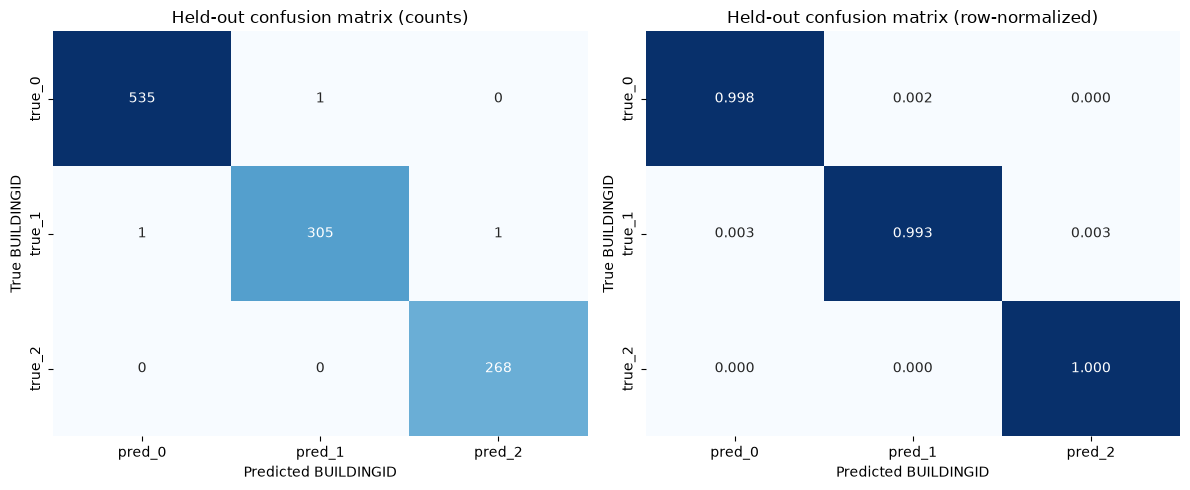

In [12]:
heldout_confusion_normalized = heldout_confusion_counts.astype(np.float64) / heldout_confusion_counts.sum(axis=1, keepdims=True)
heldout_confusion_normalized_df = pd.DataFrame(
    heldout_confusion_normalized,
    index=[f"true_{c}" for c in BUILDING_CLASSES],
    columns=[f"pred_{c}" for c in BUILDING_CLASSES],
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.heatmap(heldout_confusion_counts_df, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0])
axes[0].set(title="Held-out confusion matrix (counts)", xlabel="Predicted BUILDINGID", ylabel="True BUILDINGID")
sns.heatmap(heldout_confusion_normalized_df, annot=True, fmt=".3f", cmap="Blues", cbar=False, vmin=0, vmax=1, ax=axes[1])
axes[1].set(title="Held-out confusion matrix (row-normalized)", xlabel="Predicted BUILDINGID", ylabel="True BUILDINGID")
fig.tight_layout()
plt.show()

## 9. Summary

- **Processed inputs:** Member 1's `aml_internal_train_features.csv`,
  `aml_internal_validation_features.csv`, and `aml_heldout_validation_features.csv`
  (`GroupShuffleSplit`, groups = `(BUILDINGID, FLOOR, SPACEID)`, test_size = 0.20,
  random_state = 42, fit on `trainingData.csv` only; `validationData.csv` is the untouched
  held-out split).
- **Predictors:** the 1,046-column allowlist reconstructed from Member 1's
  `RSSI_Z__WAPnnn` / `SEEN__WAPnnn` / summary columns; targets and all identifier/metadata
  columns are excluded from the predictor matrix.
- **Model family:** Random Forest (`sklearn.ensemble.RandomForestClassifier`), chosen for
  this wide, sparse, discrete tabular Wi-Fi feature task (see Section 3).
- **Tuning protocol:** an 18-point grid over `n_estimators ∈ {100, 200, 300}`,
  `max_depth ∈ {None, 20, 30}`, `min_samples_leaf ∈ {1, 2}`, each fit on internal training
  and scored on internal validation only; selected by internal-validation accuracy with
  macro F1 as tie-break.

In [13]:
print("Selected model configuration:", BEST_PARAMS)
print(f"Held-out validation accuracy: {heldout_accuracy:.4f}")
print(f"Held-out validation macro F1: {heldout_macro_f1:.4f}")
print("Held-out confusion matrix (counts):")
print(heldout_confusion_counts_df)

Selected model configuration: {'n_estimators': 100, 'max_depth': None, 'min_samples_leaf': 1}
Held-out validation accuracy: 0.9973
Held-out validation macro F1: 0.9971
Held-out confusion matrix (counts):
        pred_0  pred_1  pred_2
true_0     535       1       0
true_1       1     305       1
true_2       0       0     268
